# GitSkills — ile skilli jest w każdym repozytorium?

Liczymy wystąpienia plików z tabeli `artifacts`: jedno repozytorium + jedna ścieżka = jeden skill.
Kopie tej samej treści pod różnymi ścieżkami liczą się osobno. Uwzględniamy cały GitSkills,
także warianty nazw, np. `skill.md`; pliki pomocnicze z `artifact_siblings` nie są skillami.

Źródło: [GitSkills / Hugging Face](https://huggingface.co/datasets/mvaccargiu/gitskills),
snapshot z lipca 2026, commit `ebab17454a7c236f8f26b183567f1a126f42e3f8`.
Pełne dane są lokalnie w `data/gitskills/`.
Przed uruchomieniem: `python -m pip install -r requirements.txt`.

In [1]:
from pathlib import Path
import json

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "gitskills"
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)

manifest = json.loads((DATA / "manifest.json").read_text(encoding="utf-8"))
assert manifest.get("download_completed_at_utc"), "Najpierw zakończ pobieranie danych."

con = duckdb.connect()
con.read_parquet(str(DATA / "data/artifacts/*.parquet")).create_view("artifacts")
con.read_parquet(str(DATA / "data/repos/*.parquet")).create_view("repos")

┌───────────────────────────────────────────┬────────────────┬───────┬───────┬─────────┬──────────────────┬────────────┬────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┬──────────────────────┬──────────────────────┬──────────────────┐
│                 full_name                 │     owner      │ stars │ forks │ is_fork │     language     │  license   │                                                                                                                                                                          description                                                                                                                                                                

## Agregacja

Jedno zapytanie liczy różne ścieżki w każdym repozytorium. `LEFT JOIN` zachowuje też
ewentualne repozytoria z zerem skilli. DuckDB odczytuje potrzebne kolumny bez ładowania treści plików.

In [2]:
skills_per_repo = con.sql("""
    SELECT r.full_name AS repo_full_name, COUNT(DISTINCT a.path) AS n_skills
    FROM repos r
    LEFT JOIN artifacts a ON a.repo_full_name = r.full_name
    GROUP BY r.full_name
    ORDER BY n_skills DESC, repo_full_name
""").df()

# Kontrola kompletności tego wydania GitSkills.
assert len(skills_per_repo) == 282_200
assert skills_per_repo["n_skills"].sum() == 3_797_117

print(f"Repozytoria: {len(skills_per_repo):,}")
print(f"Wystąpienia skilli: {skills_per_repo['n_skills'].sum():,}")
display(skills_per_repo.head(20))
display(skills_per_repo["n_skills"].describe(percentiles=[0.5, 0.9, 0.99]))

Repozytoria: 282,200
Wystąpienia skilli: 3,797,117


,repo_full_name,n_skills
0,majiayu000/claude-skill-registry-data,172267
1,David-Li0406/meta-skill-evloving,110654
2,NeuralBlitz/ncx,63128
3,gabrielmoreira/agent-skills-mirror,60655
4,NeuralBlitz/buggy,30308
5,majiayu000/claude-skill-registry,28460
6,dvcrn/openclaw-skills-marketplace,22669
7,Klotzkette/claude-fuer-deutsches-recht,21955
8,tools-only/X-Skills,21471
9,ahmedfawzy8866/arc,18603


count    282200.000000
mean         13.455411
std         452.157366
min           1.000000
50%           2.000000
90%          15.000000
99%         119.000000
max      172267.000000
Name: n_skills, dtype: float64

## Rozkład liczby skilli

Histogram pokazuje, ile repozytoriów mieści się w danym przedziale.
Skale logarytmiczne pozwalają zobaczyć zarówno małe, jak i bardzo duże wartości.

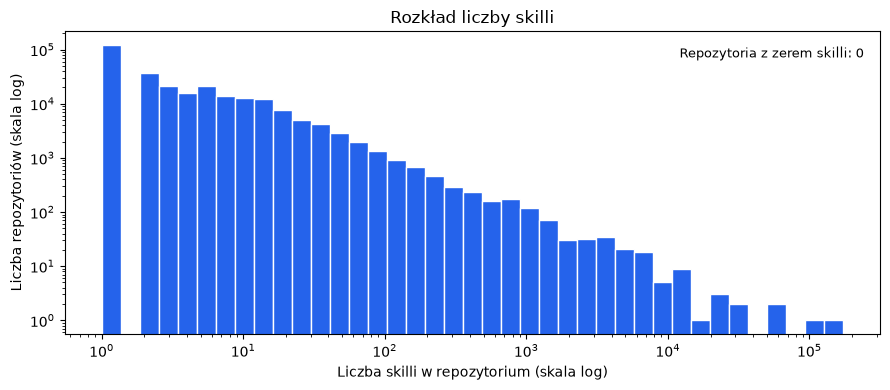

In [3]:
counts = skills_per_repo["n_skills"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(counts[counts > 0], bins=np.geomspace(1, max(2, counts.max() + 1), 40),
        color="#2563eb", edgecolor="white")
ax.set(xscale="log", yscale="log", xlabel="Liczba skilli w repozytorium (skala log)",
       ylabel="Liczba repozytoriów (skala log)", title="Rozkład liczby skilli")
ax.text(0.98, 0.95, f"Repozytoria z zerem skilli: {(counts == 0).sum():,}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "skills_histogram.png", dpi=160)
plt.show()

## Rozkład skumulowany

Dla wybranej liczby skilli na osi X odczytujemy odsetek repozytoriów,
które mają **co najwyżej tyle** skilli.

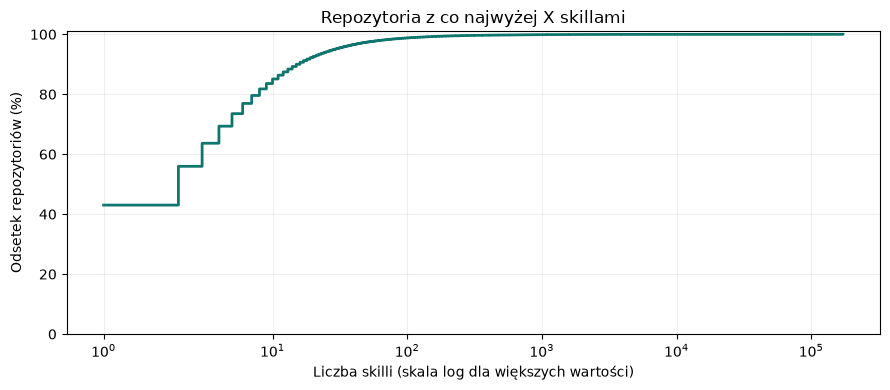

In [4]:
frequency = counts.value_counts().sort_index()
cumulative_percent = 100 * frequency.cumsum() / len(counts)

fig, ax = plt.subplots(figsize=(9, 4))
ax.step(frequency.index, cumulative_percent, where="post", color="#0f766e", linewidth=2)
ax.set(xscale="symlog", ylim=(0, 101), xlabel="Liczba skilli (skala log dla większych wartości)",
       ylabel="Odsetek repozytoriów (%)", title="Repozytoria z co najwyżej X skillami")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "skills_cumulative.png", dpi=160)
plt.show()

## Repozytoria z największą liczbą skilli

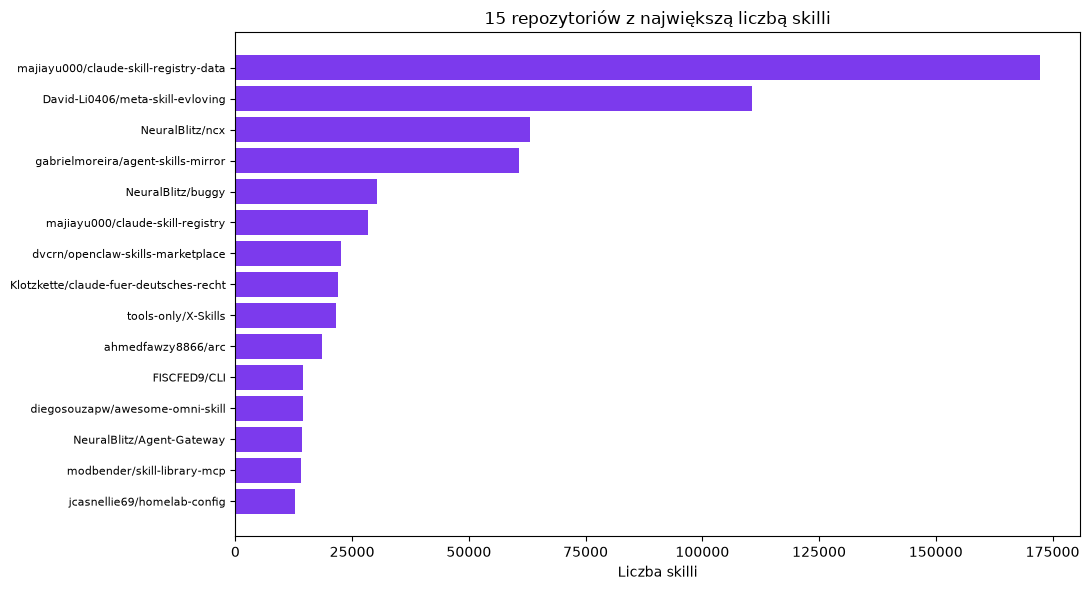

In [5]:
top = skills_per_repo.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top["repo_full_name"], top["n_skills"], color="#7c3aed")
ax.set(xlabel="Liczba skilli", title="15 repozytoriów z największą liczbą skilli")
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
fig.savefig(OUT / "skills_top_repositories.png", dpi=160)
plt.show()

## Zapis pełnego wyniku

CSV ma dwie kolumny: `repo_full_name` i `n_skills`, po jednym wierszu na repozytorium.
Wszystkie trzy wykresy są również zapisane jako PNG w `results/`.

In [6]:
skills_per_repo.to_csv(OUT / "skills_per_repository.csv", index=False)
con.register("result", skills_per_repo)
con.table("result").write_parquet(str(OUT / "skills_per_repository.parquet"), compression="zstd")
con.close()
print("Zapisano wyniki w: results/")

Zapisano wyniki w: results/
